# Assessment-Lab-3 - 11.9.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    1. Generate the model to cluster the data for the given dataset “nursery”,
       that describes the admission of children in the nursery based on the
       criteria. Use the following input features – except the target variable
       “Class”.

       Attribute Values:
       parents        usual, pretentious, great_pret
       has_nurs       proper, less_proper, improper, critical, very_crit
       form           complete, completed, incomplete, foster
       children       1, 2, 3, more
       housing        convenient, less_conv, critical
       finance        convenient, inconv
       social         non-prob, slightly_prob, problematic
       health         recommended, priority, not_recom
       Class          - Target.

       Rename the children value to categorical(1,2,3) and apply kmode
       clustering method. Find the suitable number of clusters using
       appropriate method. Display the cluster centroids and count of points
       in the clusters.

    2. Generate the model to cluster the data using agglomerative clustering
       method for the given dataset “adult”. Use the following input features -
       'workclass', 'education', 'marital.status', 'occupation', 'relationship',
       'race', 'native.country'. Analyze the performance of the data and
       visualize the results.

### 1.

### K-Modes Clustering - Nursery dataset

#### Load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from kmodes.kmodes import KModes
from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
nursery_cols = ['parents', 'has_nurs', 'form', 'children', 'housing',
                'finance', 'social', 'health', 'Class']

nursery_df = pd.read_csv('Assessment Lab 3- 11.9.26/nursery.data', header=None, names=nursery_cols)
nursery_df.head()

,parents,has_nurs,form,children,housing,finance,social,health,Class
0,usual,proper,complete,1,convenient,convenient,nonprob,recommended,recommend
1,usual,proper,complete,1,convenient,convenient,nonprob,priority,priority
2,usual,proper,complete,1,convenient,convenient,nonprob,not_recom,not_recom
3,usual,proper,complete,1,convenient,convenient,slightly_prob,recommended,recommend
4,usual,proper,complete,1,convenient,convenient,slightly_prob,priority,priority


#### Select features

In [3]:
# Drop the target variable 'Class' - clustering is unsupervised
X_nursery = nursery_df.drop(columns='Class').copy()

X_nursery.head()

,parents,has_nurs,form,children,housing,finance,social,health
0,usual,proper,complete,1,convenient,convenient,nonprob,recommended
1,usual,proper,complete,1,convenient,convenient,nonprob,priority
2,usual,proper,complete,1,convenient,convenient,nonprob,not_recom
3,usual,proper,complete,1,convenient,convenient,slightly_prob,recommended
4,usual,proper,complete,1,convenient,convenient,slightly_prob,priority


#### Rename children values to categorical(1,2,3)

In [4]:
X_nursery['children'] = X_nursery['children'].replace({'more': '3'})

X_nursery['children'].value_counts()

children
3    6480
1    3240
2    3240
Name: count, dtype: int64

#### Find suitable number of clusters

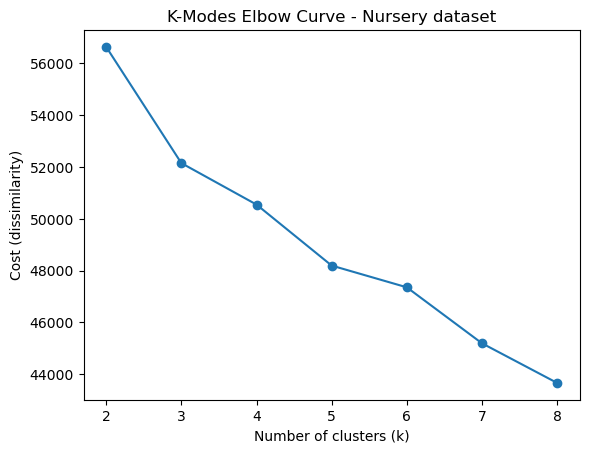

In [5]:
k_values = range(2, 9)
costs = []

for k in k_values:
    km = KModes(n_clusters=k, init='Huang', n_init=5, random_state=1265, verbose=0)
    km.fit(X_nursery)
    costs.append(km.cost_)

plt.plot(k_values, costs, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Cost (dissimilarity)')
plt.title('K-Modes Elbow Curve - Nursery dataset')
plt.show()

In [6]:
# Elbow point: the k with the largest perpendicular distance from the line
# joining the first and last point of the cost curve
k_arr = np.array(list(k_values), dtype=float)
c_arr = np.array(costs, dtype=float)

x = (k_arr - k_arr.min()) / (k_arr.max() - k_arr.min())
y = (c_arr - c_arr.min()) / (c_arr.max() - c_arr.min())

distances = np.abs((y[-1] - y[0]) * x - (x[-1] - x[0]) * y + x[-1] * y[0] - y[-1] * x[0])
distances /= np.sqrt((y[-1] - y[0]) ** 2 + (x[-1] - x[0]) ** 2)

best_k = list(k_values)[np.argmax(distances)]
print(f"Suitable number of clusters (elbow point): {best_k}")

Suitable number of clusters (elbow point): 3


#### Train final model

In [7]:
kmodes_model = KModes(n_clusters=best_k, init='Huang', n_init=5, random_state=1265, verbose=0)
cluster_labels = kmodes_model.fit_predict(X_nursery)

#### Cluster centroids & point counts

In [8]:
centroids = pd.DataFrame(kmodes_model.cluster_centroids_, columns=X_nursery.columns)
centroids.index.name = 'Cluster'
centroids

,parents,has_nurs,form,children,housing,finance,social,health
Cluster,,,,,,,,
0,usual,proper,completed,3,convenient,inconv,slightly_prob,priority
1,pretentious,less_proper,completed,3,less_conv,convenient,nonprob,recommended
2,great_pret,critical,incomplete,3,less_conv,inconv,problematic,not_recom


In [9]:
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()
cluster_counts.index.name = 'Cluster'
cluster_counts.name = 'Count'
cluster_counts

Cluster
0    5592
1    4304
2    3064
Name: Count, dtype: int64

#### Visualize results

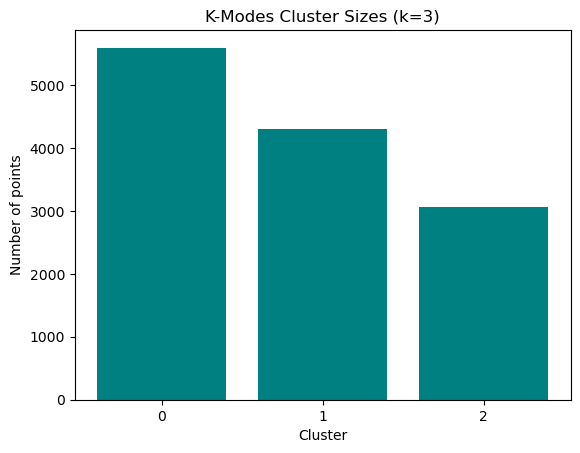

In [10]:
plt.bar(cluster_counts.index.astype(str), cluster_counts.values, color='teal')
plt.xlabel('Cluster')
plt.ylabel('Number of points')
plt.title(f'K-Modes Cluster Sizes (k={best_k})')
plt.show()

### 2.

### Agglomerative Clustering - Adult dataset

#### Load dataset

In [11]:
adult_df = pd.read_csv('Assessment Lab 3- 11.9.26/adult.csv')
adult_df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


#### Select features

In [12]:
features_adult = ['workclass', 'education', 'marital.status', 'occupation',
                   'relationship', 'race', 'native.country']

# '?' marks missing values in this dataset
X_adult = adult_df[features_adult].replace('?', np.nan).dropna()
print(f"Rows after dropping missing values: {X_adult.shape[0]}")

# Hierarchical clustering needs a full pairwise distance matrix, which is
# infeasible to compute for 30k+ rows, so a random sample is used instead
X_adult_sample = X_adult.sample(n=1000, random_state=1265)

Rows after dropping missing values: 30162


#### Encode features

In [13]:
encoder_adult = OneHotEncoder(sparse_output=False)
X_adult_encoded = encoder_adult.fit_transform(X_adult_sample)

X_adult_encoded.shape

(1000, 83)

#### Find suitable number of clusters

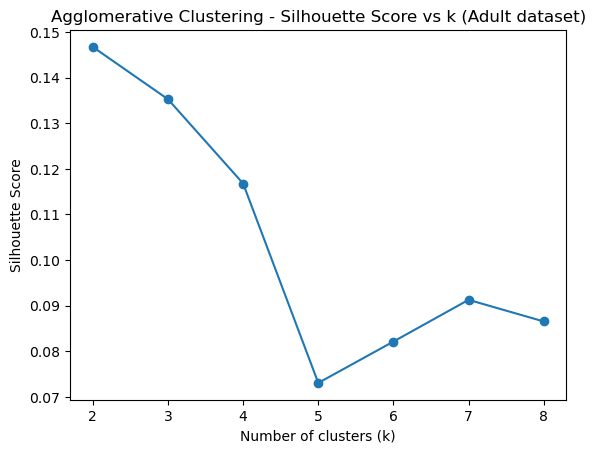

In [14]:
k_values_adult = range(2, 9)
silhouette_scores = []

for k in k_values_adult:
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = model.fit_predict(X_adult_encoded)
    silhouette_scores.append(silhouette_score(X_adult_encoded, labels))

plt.plot(k_values_adult, silhouette_scores, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Agglomerative Clustering - Silhouette Score vs k (Adult dataset)')
plt.show()

In [15]:
best_k_adult = list(k_values_adult)[np.argmax(silhouette_scores)]
print(f"Suitable number of clusters (best silhouette score): {best_k_adult}")

Suitable number of clusters (best silhouette score): 2


#### Train final model

In [16]:
agglo_model = AgglomerativeClustering(n_clusters=best_k_adult, linkage='ward')
adult_cluster_labels = agglo_model.fit_predict(X_adult_encoded)

#### Performance evaluation

In [17]:
final_silhouette = silhouette_score(X_adult_encoded, adult_cluster_labels)
print(f"Silhouette Score: {final_silhouette:.4f}")
print()

adult_cluster_counts = pd.Series(adult_cluster_labels).value_counts().sort_index()
adult_cluster_counts.index.name = 'Cluster'
adult_cluster_counts.name = 'Count'
print(adult_cluster_counts)

Silhouette Score: 0.1467

Cluster
0    592
1    408
Name: Count, dtype: int64


#### Visualize results

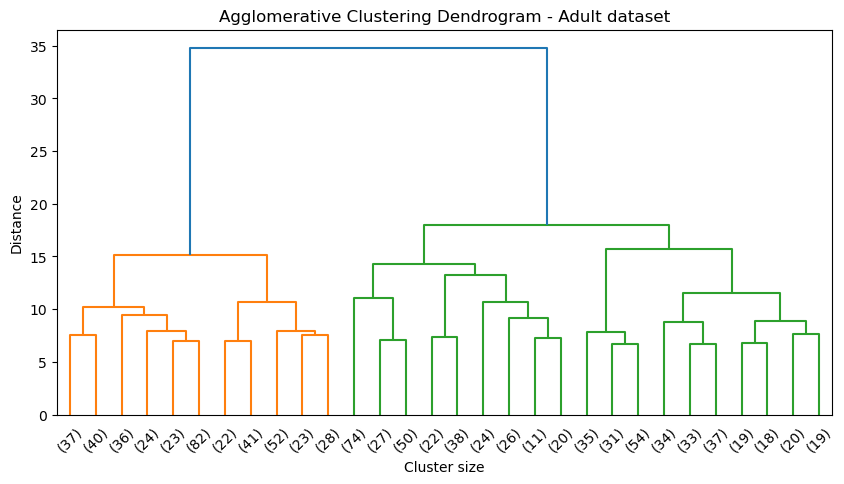

In [18]:
linked = linkage(X_adult_encoded, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(linked, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.title('Agglomerative Clustering Dendrogram - Adult dataset')
plt.show()

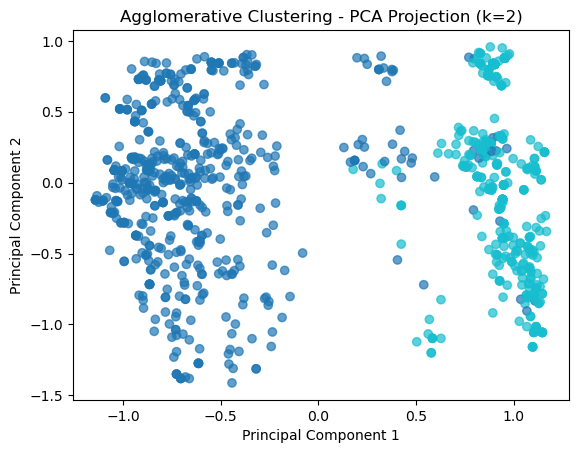

In [19]:
pca = PCA(n_components=2, random_state=1265)
X_adult_pca = pca.fit_transform(X_adult_encoded)

plt.scatter(X_adult_pca[:, 0], X_adult_pca[:, 1], c=adult_cluster_labels, cmap='tab10', alpha=0.7)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title(f'Agglomerative Clustering - PCA Projection (k={best_k_adult})')
plt.show()